<a href="https://colab.research.google.com/github/moksh033/Data-Analytics-and-Visualisation/blob/main/experiment%2011.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from matplotlib.patches import Circle

In [2]:

data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F'],
    'StudyHours': [1, 2, 3, 8, 9, 10],
    'Marks': [30, 35, 40, 80, 85, 90]
}

In [3]:
df = pd.DataFrame(data)

In [4]:
print("Student Dataset:")
print(df)

Student Dataset:
  Student  StudyHours  Marks
0       A           1     30
1       B           2     35
2       C           3     40
3       D           8     80
4       E           9     85
5       F          10     90


In [5]:
X = df[['StudyHours', 'Marks']]

In [6]:
kmeans = KMeans(
    n_clusters=2,
    init='random',
    random_state=42,
    n_init=10
)

In [7]:
df['Cluster'] = kmeans.fit_predict(X)

In [8]:
print("\nStudent Groups:")
print(df)


Student Groups:
  Student  StudyHours  Marks  Cluster
0       A           1     30        0
1       B           2     35        0
2       C           3     40        0
3       D           8     80        1
4       E           9     85        1
5       F          10     90        1


In [9]:
centroids = kmeans.cluster_centers_

In [10]:
print("\nFinal Centroids:")
print(centroids)


Final Centroids:
[[ 2. 35.]
 [ 9. 85.]]


In [11]:

plt.figure(figsize=(8, 6))

colors = ['blue', 'green']

<Figure size 800x600 with 0 Axes>

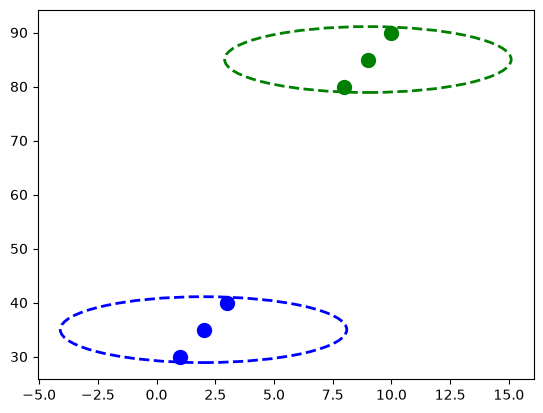

In [12]:
for cluster in range(2):

    cluster_data = df[df['Cluster'] == cluster]


    plt.scatter(
        cluster_data['StudyHours'],
        cluster_data['Marks'],
        color=colors[cluster],
        s=100,
        label=f'Cluster {cluster + 1}'
    )

    center_x = centroids[cluster, 0]
    center_y = centroids[cluster, 1]


    distances = (
        (cluster_data['StudyHours'] - center_x)**2 +
        (cluster_data['Marks'] - center_y)**2
    )**0.5

    radius = distances.max() + 1

    circle = Circle(
        (center_x, center_y),
        radius,
        fill=False,
        color=colors[cluster],
        linewidth=2,
        linestyle='--'
    )

    plt.gca().add_patch(circle)

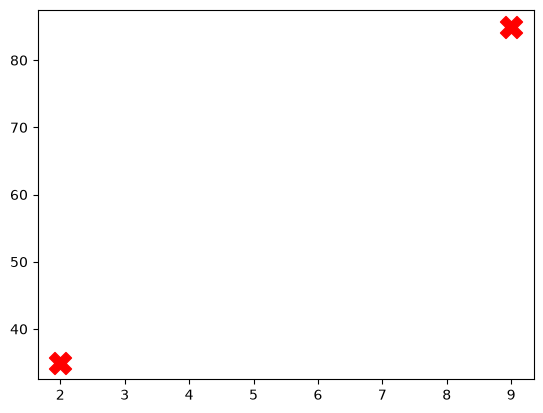

In [13]:
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

C:\Users\Asus\AppData\Local\Temp\ipykernel_46140\3082341863.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


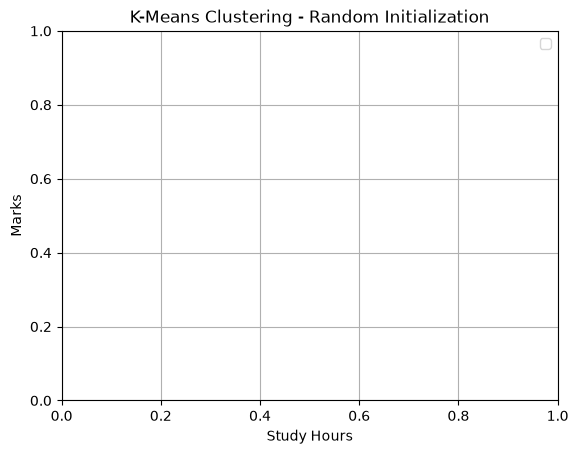

In [14]:
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.title('K-Means Clustering - Random Initialization')

plt.legend()
plt.grid(True)
plt.show()

In [15]:
wcss = []

In [16]:

for k in range(1, 7):

    model = KMeans(
        n_clusters=k,
        init='random',
        random_state=42,
        n_init=10
    )

In [17]:
model.fit(X)
wcss.append(model.inertia_)

In [18]:
# Step 8: Elbow Method - Calculate WCSS

wcss = []

for k in range(1, 7):

    model = KMeans(
        n_clusters=k,
        init='random',
        random_state=42,
        n_init=10
    )

    model.fit(X)

    wcss.append(model.inertia_)

In [19]:
# Display WCSS values

print("\nWCSS Values:")

for k, value in enumerate(wcss, start=1):
    print(f"K = {k}, WCSS = {value:.2f}")


WCSS Values:
K = 1, WCSS = 3927.50
K = 2, WCSS = 104.00
K = 3, WCSS = 65.00
K = 4, WCSS = 26.00
K = 5, WCSS = 13.00
K = 6, WCSS = 0.00


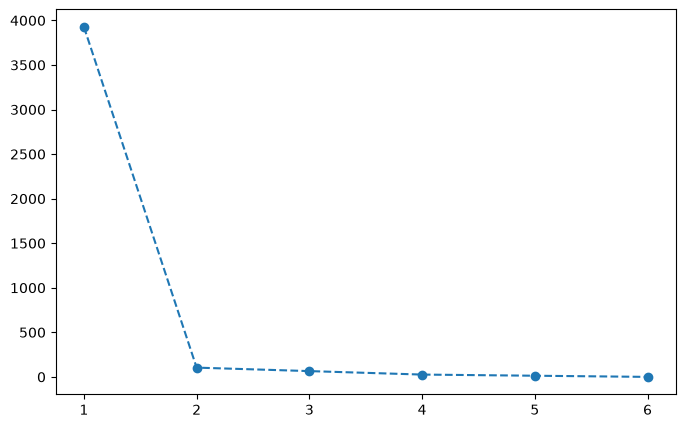

In [20]:
# Step 9: Plot Elbow Graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(wcss) + 1),
    wcss,
    marker='o',
    linestyle='--'
)

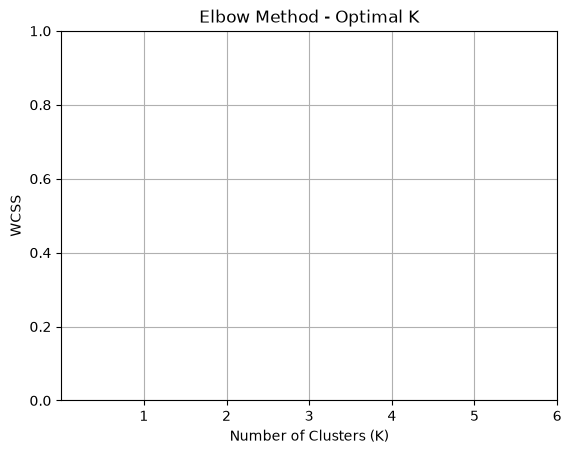

In [21]:
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method - Optimal K')

plt.xticks(range(1, len(wcss) + 1))
plt.grid(True)

plt.show()